# RAG-проект, КТ3: векторная база, эмбеддинги и sparse/dense/hybrid поиск

Сравниваю эмбеддинг модели, настройки индекса в Chroma, BM25, dense и hybrid. Всё гонял у себя на маке M4.

In [1]:
%pip install -q chromadb rank-bm25 sentence-transformers scikit-learn scipy pandas matplotlib psutil

In [2]:
import warnings
warnings.filterwarnings('ignore')
import gc, json, os, re, sys, time, pickle, subprocess, tracemalloc
os.environ['HF_HUB_DISABLE_PROGRESS_BARS'] = '1'
os.environ['TRANSFORMERS_VERBOSITY'] = 'error'
os.environ['TOKENIZERS_PARALLELISM'] = 'false'
os.environ['HF_HUB_VERBOSITY'] = 'error'
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from rank_bm25 import BM25Okapi
from scipy.stats import spearmanr
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import roc_auc_score
from sentence_transformers import SentenceTransformer
from transformers.utils import logging as hf_logging
hf_logging.disable_progress_bar()
import logging
logging.getLogger('sentence_transformers').setLevel(logging.ERROR)

%matplotlib inline
pd.set_option('display.width', 250)
pd.set_option('display.max_columns', 30)
pd.set_option('display.max_colwidth', 60)

DATA = Path('data') if Path('data').exists() else Path('../data')
CACHE = DATA / 'kt3_cache'
(CACHE / 'emb').mkdir(parents=True, exist_ok=True)
DEVICE = 'cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu'

gold = json.load(open(DATA / 'gold_set.json', encoding='utf-8'))
val_q = [g for g in gold if g['split'] == 'val']
test_q = [g for g in gold if g['split'] == 'test']
print('val:', pd.Series([g['type'] for g in val_q]).value_counts().to_dict())
print('test:', pd.Series([g['type'] for g in test_q]).value_counts().to_dict())

val: {'factual': 11, 'composite': 10, 'abstract': 7, 'negative': 7}
test: {'composite': 5, 'factual': 4, 'abstract': 3, 'negative': 3}


## 0. Что беру из КТ2

Корпус и чанки беру как получилось в итоге КТ2 и дальше их не трогаю. Корпус чищеный: без html, подписей каналов и служебных постов, keycap эмодзи переведены в цифры, остальные эмодзи убраны, дубли тоже. Режу SentenceChunker на 128 токенов, и в начало каждого чанка дописываю канал, дату, тип поста и 5 ключевых слов по TF-IDF.

Взял это потому что в КТ2 это была лучшая связка по val: у BM25 Recall@5 0.719, а на сыром корпусе было 0.661. Семантический и нейро чанкинг лучше не сделали и работали намного дольше, а дописывание метаданных помогло и BM25, и BGE-M3. Для dense в КТ2 вроде было чуть лучше эмодзи оставлять, но там разница в пару вопросов, а для hybrid мне нужен один корпус на оба поиска, так что убрал везде.

In [3]:
docs_clean, dup_map = pickle.load(open(DATA / 'kt2_cache' / 'clean_corpus.pkl', 'rb'))
chunks, _ = pickle.load(open(DATA / 'kt2_cache' / 'chunks_sentence_128.pkl', 'rb'))
STOP = set(open(DATA / 'stop_ru.txt', encoding='utf-8').read().split())
doc_text = {d['doc_id']: d['text'] for d in docs_clean}

def content_type(t):
    t = t.lower()
    if re.search(r'розыгрыш|победител|конкурс', t): return 'contest'
    if re.search(r'реклама|erid|igm\.gg|промокод', t): return 'ad'
    if re.search(r'получила скидку|покупаем за|акция продлится|топ \d+ игр до|\| -\d+% \||-\d+%\s*\|', t): return 'deal'
    if re.search(r'раздач|бесплатно|забрать', t): return 'giveaway'
    return 'news'

tf = TfidfVectorizer(max_features=30000, min_df=2, max_df=0.3, token_pattern=r'(?u)\b[а-яёa-z][а-яёa-z0-9]{2,}\b', stop_words=list(STOP))
M = tf.fit_transform([c['text'].lower() for c in chunks])
vocab = np.array(tf.get_feature_names_out())
SRC = {'egs_tg': 'Epic Games Store', 'SteamByFree': 'Халявный Steam'}
CT = {'news': 'новость', 'deal': 'скидка', 'giveaway': 'раздача', 'contest': 'розыгрыш', 'ad': 'реклама'}
texts = []
for i, c in enumerate(chunks):
    row = M.getrow(i)
    keywords = ', '.join(vocab[row.indices[np.argsort(-row.data)][:5]])
    texts.append(f"Канал: {SRC[c['source']]}. Дата: {str(c['date'])[:10]}. Тип: {CT[content_type(doc_text[c['doc_id']])]}. Ключевые слова: {keywords}.\n{c['text']}")
chunk_doc = np.array([c['doc_id'] for c in chunks])
print('постов:', len(docs_clean), '| чанков:', len(texts))
print(texts[0][:300])

постов: 1622 | чанков: 2938
Канал: Epic Games Store. Дата: 2026-09-29. Тип: новость. Ключевые слова: майнеры, трояны, мощная, проверяет, сканировать.
Находим майнеры, трояны и бэкдоры — появилась мощная утилита Scan
Она проверяет более 100 форматов файлов, умеет залезать внутрь ZIP, 7Z, ISO, DMG и других архивов, а также скани


## Как считаю метрики

Вопросы из золотого набора: на val 35 штук (28 с ответом и 7 негативных), на test 15 (12 и 3). Всё подбираю по val, test смотрю только в итоговой таблице.

Правильность считаю по постам, как в КТ2. Из выдачи убираю повторы одного поста и по топ-10 постов считаю P@k, R@k, NDCG@k для k 1, 5, 10, MAP и MRR. Это только по вопросам, где ответ есть. Выбираю везде по NDCG@5, она смотрит и сколько нужного нашли, и на каком месте.

У негативных нужного поста нет, поэтому для них смотрю, отличается ли скор первого результата от вопросов с ответом. Считаю AUC: 1 значит по скору их можно идеально отделить, 0.5 как монетку кинуть.

In [4]:
KS = (1, 5, 10)
METRICS = ['P@1', 'R@1', 'NDCG@1', 'P@5', 'R@5', 'NDCG@5', 'P@10', 'R@10', 'NDCG@10', 'MAP', 'MRR']
MAIN = ['P@5', 'R@5', 'NDCG@5', 'MAP', 'MRR']

def top_posts(idx, n=10):
    out = []
    for i in idx:
        if chunk_doc[i] not in out:
            out.append(chunk_doc[i])
    return out[:n]

def evaluate(search, qs):
    rows = []
    for g in qs:
        idx, scores = search(g['question'])
        posts = top_posts(idx)
        r = {'qid': g['qid'], 'type': g['type'], 'top1': float(scores[0])}
        rel = {dup_map.get(d, d) for d in g['relevant_doc_ids']}
        if rel:
            hits = [p in rel for p in posts]
            for k in KS:
                r[f'P@{k}'] = sum(hits[:k]) / k
                r[f'R@{k}'] = sum(hits[:k]) / len(rel)
                ideal = sum(1 / np.log2(i + 2) for i in range(min(len(rel), k)))
                r[f'NDCG@{k}'] = sum(1 / np.log2(i + 2) for i, h in enumerate(hits[:k]) if h) / ideal
            r['MAP'] = sum(sum(hits[:i + 1]) / (i + 1) for i, h in enumerate(hits) if h) / min(len(rel), 10)
            r['MRR'] = next((1 / (i + 1) for i, h in enumerate(hits) if h), 0.0)
        rows.append(r)
    return pd.DataFrame(rows)

def summary(df, cols=METRICS):
    return df[df.type != 'negative'][cols].mean().round(3)

def by_type(df, cols=('R@5', 'NDCG@5')):
    return df[df.type != 'negative'].groupby('type')[list(cols)].mean().round(3).stack()

def neg_auc(df):
    return round(roc_auc_score(df.type != 'negative', df.top1), 3)

def ranked(scores, n=50):
    idx = np.argsort(-scores)[:n]
    return idx, scores[idx]

## 1. Эмбеддинг модели

Скоры MTEB RU взял из официального репо с результатами MTEB: среднее по 23 задачам MTEB(rus, v1) и отдельно среднее по трём retrieval задачам (MIRACL, RiaNews, RuBQ), они ближе к поиску. Больше 1 млрд параметров не брал, на маке с 16 ГБ такое будет считаться очень долго.

Взял пять:
- rubert-tiny2 (29M, MTEB RU 42.4), самая маленькая, это нижняя граница;
- rubert-mini-frida (32M, 63.2), тоже маленькая, но это дистиллят FRIDA, и среди маленьких она лучшая;
- USER-bge-m3 (359M, 62.8), средняя, это BGE-M3 дообученный на русском;
- FRIDA (823M, 71.1), тяжёлая. Из того, что я смотрел до 1 млрд, она лучшая по MTEB RU, дальше идёт multilingual-e5-large-instruct с 65.0;
- BGE-M3 (568M, 61.6), её брал в КТ2, оставил чтобы сравнить.

У FRIDA и rubert-mini-frida есть префиксы search_query: и search_document:, их ставлю. Ищу тут точным перебором в numpy, чтобы сравнивать именно модели, а не индекс. Время эмбеддинга это весь корпус (2938 чанков), время запроса это медиана по 100 запросам: 50 вопросов из набора и 50 их исходных формулировок.

In [5]:
MODELS = {
    'rubert-tiny2': ('cointegrated/rubert-tiny2', '', ''),
    'rubert-mini-frida': ('sergeyzh/rubert-mini-frida', 'search_query: ', 'search_document: '),
    'USER-bge-m3': ('deepvk/USER-bge-m3', '', ''),
    'BGE-M3': ('BAAI/bge-m3', '', ''),
    'FRIDA': ('ai-forever/FRIDA', 'search_query: ', 'search_document: '),
}
MTEB_RU = {'rubert-tiny2': (42.41, 8.89), 'rubert-mini-frida': (63.24, 64.85), 'USER-bge-m3': (62.80, 73.63), 'BGE-M3': (61.57, 74.79), 'FRIDA': (71.06, 77.17)}
TIMING_QUERIES = [g['question'] for g in gold] + [g['question_orig'] for g in gold]
GOLD_QUERIES = [g['question'] for g in gold]
QPOS = {q: i for i, q in enumerate(GOLD_QUERIES)}

def embed_model(key):
    meta_path = CACHE / 'emb' / f'{key}.json'
    if meta_path.exists():
        return np.load(CACHE / 'emb' / f'{key}_docs.npy'), np.load(CACHE / 'emb' / f'{key}_gold.npy'), json.loads(meta_path.read_text())
    name, q_prompt, d_prompt = MODELS[key]
    model = SentenceTransformer(name, device=DEVICE)
    model.max_seq_length = 512
    encode = lambda xs, prompt, bs=32: model.encode(xs, prompt=prompt, batch_size=bs, normalize_embeddings=True, convert_to_numpy=True, show_progress_bar=False)
    encode(texts[:32], d_prompt)
    t0 = time.time()
    E = encode(texts, d_prompt)
    corpus_s = time.time() - t0
    times = []
    for q in TIMING_QUERIES:
        t0 = time.perf_counter()
        encode([q], q_prompt, 1)
        times.append(time.perf_counter() - t0)
    Q = encode(GOLD_QUERIES, q_prompt)
    params = sum(p.numel() for p in model.parameters())
    meta = {'params_m': round(params / 1e6, 1), 'size_mb': round(sum(p.numel() * p.element_size() for p in model.parameters()) / 2**20),
            'dim': int(E.shape[1]), 'corpus_s': round(corpus_s, 1), 'query_ms': round(1000 * float(np.median(times)), 1)}
    np.save(CACHE / 'emb' / f'{key}_docs.npy', E.astype(np.float32))
    np.save(CACHE / 'emb' / f'{key}_gold.npy', Q.astype(np.float32))
    np.save(CACHE / 'emb' / f'{key}_timing.npy', encode(TIMING_QUERIES, q_prompt).astype(np.float32))
    meta_path.write_text(json.dumps(meta))
    del model
    gc.collect()
    if DEVICE == 'mps':
        torch.mps.empty_cache()
    return E, Q, meta

In [6]:
EMB, model_rows, model_evals = {}, [], {}
for key in MODELS:
    E, Q, meta = embed_model(key)
    EMB[key] = (E, Q)
    exact = lambda q, E=E, Q=Q: ranked(E @ Q[QPOS[q]])
    model_evals[key] = evaluate(exact, val_q)
    model_rows.append({'модель': key, 'параметры, M': meta['params_m'], 'размер, МБ': meta['size_mb'], 'dim': meta['dim'],
                       'MTEB RU': MTEB_RU[key][0], 'MTEB RU retrieval': MTEB_RU[key][1], 'эмбеддинг корпуса, с': meta['corpus_s'],
                       'запрос, мс': meta['query_ms'], **summary(model_evals[key], MAIN)})
model_table = pd.DataFrame(model_rows)
model_table

,модель,"параметры, M","размер, МБ",dim,MTEB RU,MTEB RU retrieval,"эмбеддинг корпуса, с","запрос, мс",P@5,R@5,NDCG@5,MAP,MRR
0,rubert-tiny2,29.2,111,312,42.41,8.89,2.7,3.5,0.143,0.518,0.438,0.391,0.478
1,rubert-mini-frida,32.3,123,312,63.24,64.85,3.8,5.5,0.207,0.671,0.660,0.637,0.712
2,USER-bge-m3,359.0,1370,1024,62.80,73.63,70.9,26.0,0.221,0.711,0.664,0.624,0.690
3,BGE-M3,567.8,2166,1024,61.57,74.79,71.1,26.2,0.214,0.693,0.667,0.629,0.726
4,FRIDA,823.4,3141,1536,71.06,77.17,206.3,46.2,0.214,0.699,0.675,0.645,0.721


rubert-tiny2 сильно хуже остальных, NDCG@5 0.438, у остальных 0.660-0.675. У неё и в MTEB retrieval всего 8.9, её под поиск особо не учили.

Остальные четыре почти одинаковые: NDCG@5 от 0.660 до 0.675, а по Recall@5 лучше всех вообще USER-bge-m3 (0.711).

Зато по скорости разница огромная. rubert-mini-frida весит 123 МБ, весь корпус делает за 3.8 сек и запрос за 5.5 мс, а FRIDA весит 3141 МБ, корпус 206 сек и запрос 46 мс.

In [7]:
for col in ['MTEB RU', 'MTEB RU retrieval']:
    for m in ['NDCG@5', 'R@5']:
        rho, p = spearmanr(model_table[col], model_table[m])
        print(f'Спирмен {col} и val {m}: {rho:.2f} (p={p:.2f})')
print()
model_table.sort_values('MTEB RU', ascending=False)[['модель', 'MTEB RU', 'MTEB RU retrieval', 'NDCG@5', 'R@5']]

Спирмен MTEB RU и val NDCG@5: 0.60 (p=0.28)
Спирмен MTEB RU и val R@5: 0.50 (p=0.39)
Спирмен MTEB RU retrieval и val NDCG@5: 1.00 (p=0.00)
Спирмен MTEB RU retrieval и val R@5: 0.70 (p=0.19)



,модель,MTEB RU,MTEB RU retrieval,NDCG@5,R@5
4,FRIDA,71.06,77.17,0.675,0.699
1,rubert-mini-frida,63.24,64.85,0.660,0.671
2,USER-bge-m3,62.80,73.63,0.664,0.711
3,BGE-M3,61.57,74.79,0.667,0.693
0,rubert-tiny2,42.41,8.89,0.438,0.518


Совпадает ли MTEB с моим корпусом. С общим MTEB RU корреляция Спирмена с NDCG@5 на val 0.60, а с retrieval частью 1.00, то есть по retrieval задачам порядок моделей такой же, как у меня. Но разрыв совсем разный: в MTEB между rubert-mini-frida и FRIDA 12 пунктов по retrieval (64.9 и 77.2), а у меня 0.015 по NDCG@5.

В общий скор MTEB входят классификация и кластеризация, к поиску они отношения не имеют, поэтому rubert-mini-frida там выше USER-bge-m3 и BGE-M3, а на поиске у меня чуть ниже. Ну и корпус для dense простой, посты короткие и почти в каждом вопросе есть название игры. Так что сильная модель тут почти ничего не выигрывает, а модель, которую под поиск не учили (rubert-tiny2), сразу проваливается.

Дальше беру FRIDA, по NDCG@5 на val она лучшая, хоть и чуть-чуть.

In [8]:
BEST_MODEL = model_table.sort_values(['NDCG@5', 'R@5'], ascending=False).iloc[0]['модель']
E_best, Q_best = EMB[BEST_MODEL]
print('лучшая модель по val NDCG@5:', BEST_MODEL)

лучшая модель по val NDCG@5: FRIDA


## 2. Векторная БД

Взял Chroma: работает прямо в питоне без сервера, запускается в колабе, и в ней можно настраивать HNSW. Qdrant без сервера ищет просто перебором, там настройки индекса ничего не меняют.

Сравниваю три настройки HNSW (M это сколько связей у каждой точки в графе, ef_construction и ef_search это насколько широко он ищет при построении и при запросе):
- быстрая: M=8, ef_construction=16, ef_search=16;
- средняя: M=16, ef_construction=100, ef_search=100, это дефолт Chroma;
- точная: M=48, ef_construction=400, ef_search=400.

Каждую гоняю в отдельном процессе, чтобы честно мерить память. Меряю время индексации всего корпуса, медиану времени запроса по тем же 100 запросам (только поиск в индексе, без эмбеддинга), пиковую память процесса при индексации (ru_maxrss) и насколько она выросла, плюс Recall@5 и NDCG@5 на val. Запрашиваю 50 чанков, столько же потом берёт поиск, чтобы после удаления повторов осталось 10 постов. Ещё смотрю, насколько топ-10 индекса совпадает с точным перебором, так видно, сколько он теряет. Для сравнения есть точный перебор в numpy, там память это просто размер матрицы. Векторы от FRIDA.

In [9]:
BENCH = CACHE / 'chroma_bench.py'
BENCH.write_text("""import sys, json, time, resource
import numpy as np, psutil, chromadb
emb, timing, goldq, m, efc, efs, frac, out = sys.argv[1:]
E, Qt, Qg = np.load(emb), np.load(timing), np.load(goldq)
ids = np.random.default_rng(42).permutation(len(E))[:max(1, round(float(frac) * len(E)))]
proc = psutil.Process()
col = chromadb.EphemeralClient().create_collection('bench', embedding_function=None, configuration={'hnsw': {
    'space': 'cosine', 'max_neighbors': int(m), 'ef_construction': int(efc), 'ef_search': int(efs)}})
base = proc.memory_info().rss
t0 = time.time()
for i in range(0, len(ids), 1000):
    part = ids[i:i + 1000]
    col.add(ids=[str(j) for j in part], embeddings=E[part])
index_s = time.time() - t0
peak = resource.getrusage(resource.RUSAGE_SELF).ru_maxrss * (1 if sys.platform == 'darwin' else 1024)
n_results = min(50, len(ids))
col.query(query_embeddings=Qt[:1], n_results=n_results)
times = []
for q in Qt:
    t0 = time.perf_counter()
    col.query(query_embeddings=[q], n_results=n_results, include=['distances'])
    times.append(time.perf_counter() - t0)
res = col.query(query_embeddings=Qg, n_results=n_results, include=['distances'])
json.dump({'n': len(ids), 'index_s': index_s, 'query_ms': 1000 * float(np.median(times)), 'rss_base_mb': base / 2**20,
           'rss_peak_mb': peak / 2**20, 'ids': [[int(x) for x in r] for r in res['ids']], 'dist': res['distances']}, open(out, 'w'))
""")

def chroma_run(key, m, efc, efs, frac=1.0):
    out = CACHE / f'chroma_{key}_{m}_{efc}_{efs}_{frac}.json'
    if not out.exists():
        emb = CACHE / 'emb' / f'{key}'
        subprocess.run([sys.executable, str(BENCH), f'{emb}_docs.npy', f'{emb}_timing.npy', f'{emb}_gold.npy', str(m), str(efc), str(efs), str(frac), str(out)], check=True)
    return json.loads(out.read_text())

def chroma_search(res):
    return lambda q: (np.array(res['ids'][QPOS[q]]), 1 - np.array(res['dist'][QPOS[q]]))

def ann_recall(res, E, Q, k=10):
    exact = np.argsort(-(Q @ E.T), axis=1)[:, :k]
    return np.mean([len(set(r[:k]) & set(e)) / k for r, e in zip(res['ids'], exact)])

In [10]:
INDEX_CONFIGS = {'быстрый M=8 ef=16': (8, 16, 16), 'средний M=16 ef=100': (16, 100, 100), 'точный M=48 ef=400': (48, 400, 400)}
CHROMA, index_rows = {}, []
for name, (m, efc, efs) in INDEX_CONFIGS.items():
    res = CHROMA[name] = chroma_run(BEST_MODEL, m, efc, efs)
    index_rows.append({'индекс': name, 'индексация, с': round(res['index_s'], 2), 'запрос, мс (медиана из 100)': round(res['query_ms'], 2),
                       'RAM пик, МБ': round(res['rss_peak_mb']), 'RAM прирост, МБ': round(res['rss_peak_mb'] - res['rss_base_mb']),
                       'совпадение с точным топ-10': round(ann_recall(res, E_best, Q_best), 3), **summary(evaluate(chroma_search(res), val_q), ['R@5', 'NDCG@5'])})
exact = lambda q: ranked(E_best @ Q_best[QPOS[q]])
index_rows.append({'индекс': 'точный перебор numpy', 'RAM прирост, МБ': round(E_best.nbytes / 2**20, 1), 'совпадение с точным топ-10': 1.0,
                   **summary(evaluate(exact, val_q), ['R@5', 'NDCG@5'])})
index_table = pd.DataFrame(index_rows)
index_table

,индекс,"индексация, с","запрос, мс (медиана из 100)","RAM пик, МБ","RAM прирост, МБ",совпадение с точным топ-10,R@5,NDCG@5
0,быстрый M=8 ef=16,0.28,0.60,219.0,106.0,0.834,0.664,0.640
1,средний M=16 ef=100,0.67,1.41,207.0,90.0,0.994,0.699,0.675
2,точный M=48 ef=400,1.18,3.08,212.0,95.0,1.000,0.699,0.675
3,точный перебор numpy,NaN,NaN,NaN,17.2,1.000,0.699,0.675


Быстрая экономит время, но теряет качество: её топ-10 совпадает с точным только на 83%, и NDCG@5 падает с 0.675 до 0.640.

Средняя почти точная (совпадение 99%), и метрики те же, что у перебора. Точная в 2.2 раза медленнее на запросе (3.1 мс против 1.4) и ничего не добавляет.

По памяти все три почти одинаковые, прирост 90-106 МБ, разница в пределах погрешности. Сами векторы весят 17 МБ, остальное съедает сама Chroma.

Беру среднюю, она самая быстрая из тех, что не теряют качество.

Дальше масштабирование: индексирую 10, 25, 50 и 100% корпуса средней настройкой.

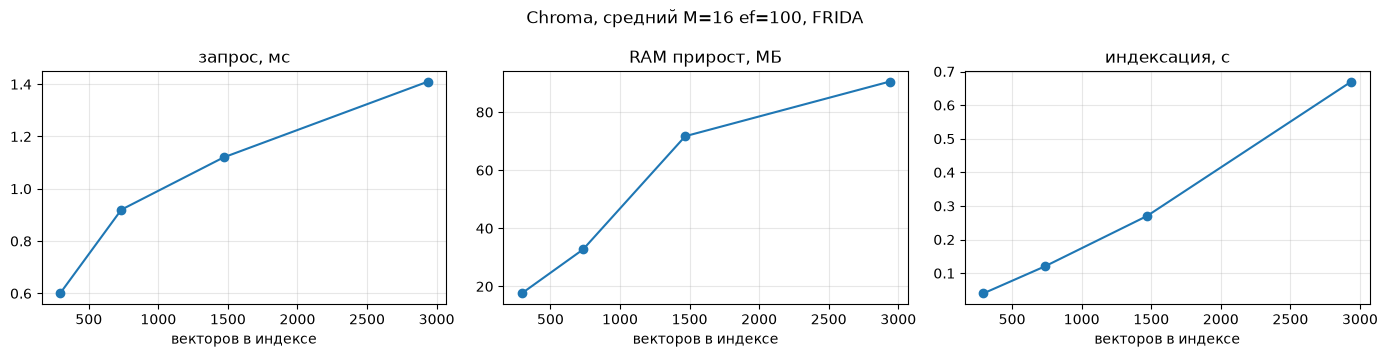

,доля корпуса,векторов,"индексация, с","запрос, мс","RAM прирост, МБ"
0,0.10,294,0.04,0.60,17.6
1,0.25,734,0.12,0.92,32.7
2,0.50,1469,0.27,1.12,71.7
3,1.00,2938,0.67,1.41,90.5


In [11]:
SCALE_CONFIG = 'средний M=16 ef=100'
m, efc, efs = INDEX_CONFIGS[SCALE_CONFIG]
scale_rows = []
for frac in [0.1, 0.25, 0.5, 1.0]:
    res = chroma_run(BEST_MODEL, m, efc, efs, frac)
    scale_rows.append({'доля корпуса': frac, 'векторов': res['n'], 'индексация, с': round(res['index_s'], 2), 'запрос, мс': round(res['query_ms'], 2),
                       'RAM прирост, МБ': round(res['rss_peak_mb'] - res['rss_base_mb'], 1)})
scale_table = pd.DataFrame(scale_rows)

fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
for ax, col in zip(axes, ['запрос, мс', 'RAM прирост, МБ', 'индексация, с']):
    ax.plot(scale_table['векторов'], scale_table[col], marker='o')
    ax.set_title(col); ax.set_xlabel('векторов в индексе'); ax.grid(alpha=0.3)
plt.suptitle(f'Chroma, {SCALE_CONFIG}, {BEST_MODEL}'); plt.tight_layout(); plt.show()
scale_table

Запрос растёт медленнее корпуса: на 294 векторах 0.60 мс, на 2938 уже 1.41 мс, данных в 10 раз больше, а запрос медленнее в 2.4 раза. Память тоже растёт медленнее, 18 МБ на 10% и 91 МБ на 100%. А индексация наоборот быстрее, 0.04 сек на 10% и 0.67 сек на 100%, в 17 раз при данных в 10 раз больше. Для нашего корпуса это всё копейки.

## 3. BM25

rank-bm25, токены это слова в нижнем регистре, индекс по тем же чанкам. Перебираю k1 и b:
- k1 отвечает за то, как быстро повтор слова перестаёт добавлять скор. Обычно ставят 1.2-2.0, но у меня чанки короткие и слова там редко повторяются, поэтому взял шире, от 0.3 до 3.0;
- b это насколько учитывать длину чанка, от 0 (не учитывать) до 1 (полностью). Это весь диапазон, шаг 0.25.

Выбираю по NDCG@5 на val.

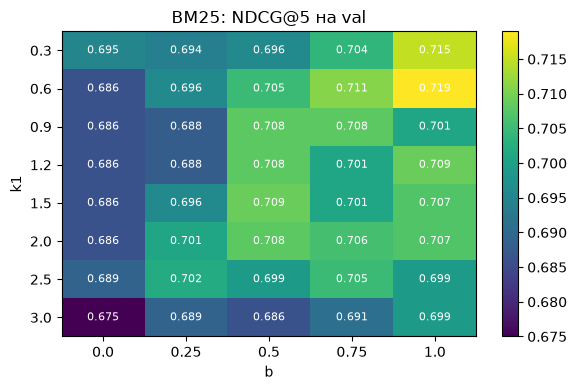

b,0.00,0.25,0.50,0.75,1.00
k1,,,,,
0.3,0.695,0.694,0.696,0.704,0.715
0.6,0.686,0.696,0.705,0.711,0.719
0.9,0.686,0.688,0.708,0.708,0.701
1.2,0.686,0.688,0.708,0.701,0.709
1.5,0.686,0.696,0.709,0.701,0.707
2.0,0.686,0.701,0.708,0.706,0.707
2.5,0.689,0.702,0.699,0.705,0.699
3.0,0.675,0.689,0.686,0.691,0.699


In [12]:
WORD = re.compile(r'\w+')
bm25_tok = lambda t: WORD.findall(t.lower()) or ['_']
tokens = [bm25_tok(t) for t in texts]

K1 = [0.3, 0.6, 0.9, 1.2, 1.5, 2.0, 2.5, 3.0]
B = [0.0, 0.25, 0.5, 0.75, 1.0]
grid = pd.DataFrame(index=K1, columns=B, dtype=float)
for k1 in K1:
    for b in B:
        bm = BM25Okapi(tokens, k1=k1, b=b)
        grid.loc[k1, b] = summary(evaluate(lambda q, bm=bm: ranked(bm.get_scores(bm25_tok(q))), val_q), ['NDCG@5'])['NDCG@5']
grid.index.name, grid.columns.name = 'k1', 'b'

fig, ax = plt.subplots(figsize=(6, 4))
im = ax.imshow(grid.values.astype(float), cmap='viridis', aspect='auto')
ax.set_xticks(range(len(B)), B); ax.set_yticks(range(len(K1)), K1); ax.set_xlabel('b'); ax.set_ylabel('k1')
for i in range(len(K1)):
    for j in range(len(B)):
        ax.text(j, i, f'{grid.iloc[i, j]:.3f}', ha='center', va='center', color='white', fontsize=8)
ax.set_title('BM25: NDCG@5 на val'); plt.colorbar(im); plt.tight_layout(); plt.show()
grid

In [13]:
best_k1, best_b = grid.stack().idxmax()
COST_PATH = CACHE / 'bm25_cost.json'
BM25_COST = json.loads(COST_PATH.read_text()) if COST_PATH.exists() else {}
def bm25_build(k1, b):
    t0 = time.time()
    bm = BM25Okapi(tokens, k1=k1, b=b)
    build_s = time.time() - t0
    key = f'{k1}_{b}'
    if key not in BM25_COST:
        tracemalloc.start()
        BM25Okapi(tokens, k1=k1, b=b)
        ram_mb = tracemalloc.get_traced_memory()[1] / 2**20
        tracemalloc.stop()
        times = []
        for q in TIMING_QUERIES:
            t0 = time.perf_counter()
            bm.get_scores(bm25_tok(q))
            times.append(time.perf_counter() - t0)
        BM25_COST[key] = [build_s, 1000 * float(np.median(times)), ram_mb]
        COST_PATH.write_text(json.dumps(BM25_COST))
    return bm, *BM25_COST[key]

bm_default, *bm_default_cost = bm25_build(1.5, 0.75)
bm_best, *bm_best_cost = bm25_build(best_k1, best_b)
bm25_search = lambda q: ranked(bm_best.get_scores(bm25_tok(q)))
bm_rows = []
for name, bm, (build_s, query_ms, ram_mb) in [('BM25 k1=1.5 b=0.75 (по умолчанию)', bm_default, bm_default_cost), (f'BM25 k1={best_k1} b={best_b}', bm_best, bm_best_cost)]:
    bm_rows.append({'конфигурация': name, 'индексация, с': round(build_s, 2), 'запрос, мс': round(query_ms, 2), 'RAM, МБ': round(ram_mb, 1),
                    **summary(evaluate(lambda q, bm=bm: ranked(bm.get_scores(bm25_tok(q))), val_q), MAIN)})
pd.DataFrame(bm_rows)

,конфигурация,"индексация, с","запрос, мс","RAM, МБ",P@5,R@5,NDCG@5,MAP,MRR
0,BM25 k1=1.5 b=0.75 (по умолчанию),0.01,1.65,4.2,0.229,0.719,0.701,0.683,0.730
1,BM25 k1=0.6 b=1.0,0.01,1.64,4.2,0.236,0.737,0.719,0.697,0.744


Лучше всего k1=0.6 и b=1.0: NDCG@5 0.719, а с дефолтными k1=1.5 и b=0.75 было 0.701, Recall@5 0.737 против 0.719. Маленький k1 для коротких чанков логично, важно есть ли в чанке слово из вопроса (например название игры), а не сколько раз оно там. Но вся сетка в узком диапазоне от 0.675 до 0.719, BM25 к параметрам не особо чувствительный, и выигрыш над дефолтом небольшой. Индекс строится за 0.01 сек, запрос 1.6 мс, памяти около 4 МБ.

## 4. Dense

Тут ничего нового не подбираю, просто беру то, что уже нашёл: лучшая модель по val это FRIDA, индекс Chroma средний (M=16, ef=100), самый быстрый из тех, что не теряют качество.

In [14]:
chroma_rows = index_table.dropna(subset=['запрос, мс (медиана из 100)'])
ok = chroma_rows[(chroma_rows['NDCG@5'] == chroma_rows['NDCG@5'].max()) & (chroma_rows['совпадение с точным топ-10'] >= 0.95)]
BEST_INDEX = ok.sort_values('запрос, мс (медиана из 100)').iloc[0]['индекс']
dense_res = CHROMA[BEST_INDEX]
dense_search = chroma_search(dense_res)
print('dense:', BEST_MODEL, '+ Chroma', BEST_INDEX)
summary(evaluate(dense_search, val_q), MAIN)

dense: FRIDA + Chroma средний M=16 ef=100


P@5       0.214
R@5       0.699
NDCG@5    0.675
MAP       0.645
MRR       0.721
dtype: float64

## 5. Hybrid

Склеиваю BM25 и dense двумя способами, оба по топ-50 чанков от каждого:
- RRF: скор чанка это сумма 1/(60 + место) по обоим спискам, веса подбирать не надо;
- взвешенная сумма: скоры каждого списка привожу к 0-1 (min-max внутри запроса) и складываю как alpha * dense + (1 - alpha) * BM25, alpha перебираю от 0 до 1 с шагом 0.1.

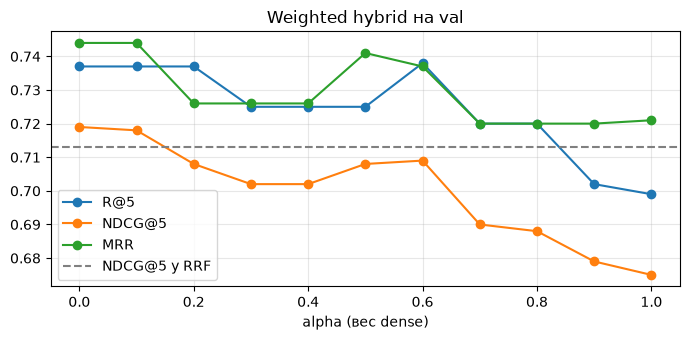

лучший alpha по val NDCG@5 среди всех: 0.0 | среди смесей 0 < alpha < 1: 0.1


,alpha,R@5,NDCG@5,MRR
0,0.0,0.737,0.719,0.744
1,0.1,0.737,0.718,0.744
2,0.2,0.737,0.708,0.726
3,0.3,0.725,0.702,0.726
4,0.4,0.725,0.702,0.726
5,0.5,0.725,0.708,0.741
6,0.6,0.738,0.709,0.737
7,0.7,0.720,0.690,0.720
8,0.8,0.720,0.688,0.720
9,0.9,0.702,0.679,0.720


In [15]:
def rrf(searches, q, k=60):
    score = {}
    for search in searches:
        for rank, i in enumerate(search(q)[0]):
            score[i] = score.get(i, 0) + 1 / (k + rank + 1)
    idx = np.array(sorted(score, key=score.get, reverse=True)[:50])
    return idx, np.array([score[i] for i in idx])

fuse_rrf = lambda q: rrf([bm25_search, dense_search], q)

def minmax(s):
    return (s - s.min()) / (s.max() - s.min() + 1e-9)

def fuse_weighted(q, alpha):
    score = {}
    for w, (idx, s) in ((1 - alpha, bm25_search(q)), (alpha, dense_search(q))):
        for i, v in zip(idx, minmax(s)):
            score[i] = score.get(i, 0) + w * v
    idx = np.array(sorted(score, key=score.get, reverse=True)[:50])
    return idx, np.array([score[i] for i in idx])

ALPHAS = np.round(np.arange(0, 1.01, 0.1), 1)
alpha_rows = [{'alpha': a, **summary(evaluate(lambda q, a=a: fuse_weighted(q, a), val_q), ['R@5', 'NDCG@5', 'MRR'])} for a in ALPHAS]
alpha_table = pd.DataFrame(alpha_rows)
top_alpha = float(alpha_table.sort_values(['NDCG@5', 'R@5'], ascending=False).iloc[0]['alpha'])
mixed = alpha_table[(alpha_table.alpha > 0) & (alpha_table.alpha < 1)]
best_alpha = float(mixed.sort_values(['NDCG@5', 'R@5'], ascending=False).iloc[0]['alpha'])

fig, ax = plt.subplots(figsize=(7, 3.5))
for col in ['R@5', 'NDCG@5', 'MRR']:
    ax.plot(alpha_table['alpha'], alpha_table[col], marker='o', label=col)
ax.axhline(summary(evaluate(fuse_rrf, val_q), ['NDCG@5'])['NDCG@5'], color='gray', ls='--', label='NDCG@5 у RRF')
ax.set_xlabel('alpha (вес dense)'); ax.set_title('Weighted hybrid на val'); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()
print('лучший alpha по val NDCG@5 среди всех:', top_alpha, '| среди смесей 0 < alpha < 1:', best_alpha)
alpha_table

alpha=1 это чистый dense, alpha=0 чистый BM25. Лучший NDCG@5 на val как раз при alpha=0 (0.719), то есть взвешенная сумма ничего не добавила к BM25. Dense на val слабее, и когда добавляешь его скор, нужные посты в среднем немного съезжают вниз, хотя при alpha=0.6 Recall@5 самый высокий (0.738). Для сравнения дальше беру лучший alpha среди настоящих смесей, это 0.1 (NDCG@5 0.718), но по сути это тот же BM25.

Дальше сравниваю пайплайны на val по всем метрикам, по типам вопросов и по отдельным вопросам, где они расходятся:

In [16]:
PIPELINES = {'BM25': bm25_search, 'dense': dense_search, 'hybrid RRF': fuse_rrf, f'hybrid weighted a={best_alpha}': lambda q: fuse_weighted(q, best_alpha)}
pipe_evals = {name: evaluate(search, val_q) for name, search in PIPELINES.items()}
pipe_table = pd.DataFrame([{'пайплайн': name, **summary(e), 'AUC негативных': neg_auc(e)} for name, e in pipe_evals.items()])
pipe_table

,пайплайн,P@1,R@1,NDCG@1,P@5,R@5,NDCG@5,P@10,R@10,NDCG@10,MAP,MRR,AUC негативных
0,BM25,0.714,0.530,0.714,0.236,0.737,0.719,0.121,0.754,0.724,0.697,0.744,0.765
1,dense,0.679,0.512,0.679,0.214,0.699,0.675,0.114,0.729,0.687,0.645,0.721,0.832
2,hybrid RRF,0.714,0.530,0.714,0.236,0.743,0.713,0.125,0.763,0.721,0.684,0.744,0.625
3,hybrid weighted a=0.1,0.714,0.530,0.714,0.236,0.737,0.718,0.121,0.754,0.723,0.694,0.744,0.617


In [17]:
pd.DataFrame({name: by_type(e, ['R@5', 'NDCG@5', 'MRR']) for name, e in pipe_evals.items()}).T

type                  abstract               composite              factual              
                           R@5 NDCG@5    MRR       R@5 NDCG@5   MRR     R@5 NDCG@5    MRR
BM25                     0.018  0.024  0.048     0.950  0.904  0.95   1.000  0.993  1.000
dense                    0.036  0.022  0.029     0.883  0.837  0.95   0.955  0.944  0.955
hybrid RRF               0.018  0.019  0.046     0.967  0.898  0.95   1.000  0.986  1.000
hybrid weighted a=0.1    0.018  0.024  0.048     0.950  0.904  0.95   1.000  0.989  1.000

In [18]:
by_q = {k: pipe_evals[k].set_index('qid') for k in ['BM25', 'dense', 'hybrid RRF']}
for g in val_q:
    if g['type'] == 'negative':
        continue
    vals = {k: (round(e.loc[g['qid'], 'R@5'], 2), round(e.loc[g['qid'], 'MRR'], 2)) for k, e in by_q.items()}
    if len(set(vals.values())) > 1:
        print(g['qid'], g['type'], '|', g['question'][:55], '|', ' | '.join(f'{k}: R@5 {r}, MRR {m}' for k, (r, m) in vals.items()))

q13 factual | Скидка Beholder 3 Steam | BM25: R@5 1.0, MRR 1.0 | dense: R@5 0.5, MRR 0.5 | hybrid RRF: R@5 1.0, MRR 1.0
q16 composite | Аналитики в январе 2026 года предсказывали выход крупно | BM25: R@5 0.5, MRR 1.0 | dense: R@5 1.0, MRR 1.0 | hybrid RRF: R@5 1.0, MRR 1.0
q25 composite | По подборкам сикдок в Steam, которые дйствуют до 26 сен | BM25: R@5 1.0, MRR 1.0 | dense: R@5 0.33, MRR 1.0 | hybrid RRF: R@5 0.67, MRR 1.0
q28 composite | Какие игры раздавались бесплатно в Epic Games Store в п | BM25: R@5 1.0, MRR 1.0 | dense: R@5 0.5, MRR 1.0 | hybrid RRF: R@5 1.0, MRR 1.0
q37 abstract | Какие жанры игр наиболее часто представлены в тематичес | BM25: R@5 0.12, MRR 0.33 | dense: R@5 0.0, MRR 0.0 | hybrid RRF: R@5 0.12, MRR 0.2
q39 abstract | Чё вообще будет с игровой индустрией когда выйдет GTA 6 | BM25: R@5 0.0, MRR 0.0 | dense: R@5 0.0, MRR 0.0 | hybrid RRF: R@5 0.0, MRR 0.12
q40 abstract | С какими трудностями столкнулась рокстар в процессе раз | BM25: R@5 0.0, MRR 0.0 | dense: R

По типам:
- фактические: BM25 и hybrid находят все нужные посты (Recall@5 1.0), dense теряет один пост в q13 (Скидка Beholder 3 Steam). Короткий запрос с названием игры, тут точное совпадение слов сильнее смысла. Hybrid тут на уровне BM25;
- составные: тут hybrid RRF лучше обоих по Recall@5 (0.967, у BM25 0.950, у dense 0.883). Составному вопросу нужно два поста, и BM25 с dense часто находят разные. Например в q16 BM25 нашёл один пост из двух, dense оба, и RRF тоже оба. Но в q25 с опечатками (сикдок, дйствуют) dense нашёл только 1 пост из 3, и RRF из-за него потерял один пост, который BM25 находил. По NDCG@5 RRF на составных чуть ниже BM25 (0.898 против 0.904);
- абстрактные: никто не находит, Recall@5 от 0.018 до 0.036. Оба мимо, складывать нечего;
- негативные: лучше всех их отличает dense (AUC 0.832), у BM25 0.765, а у hybrid всего 0.625 и 0.617. У RRF скор зависит только от мест в списках, а не от того, насколько чанк похож на вопрос, а во взвешенной сумме скоры нормированы внутри запроса, и у первого результата он почти всегда около максимума. Так что по скору hybrid вопрос без ответа не отличить.

Взвешенная сумма с alpha=0.1 по типам почти как BM25, ни на одном типе выигрыша нет.

## 6. Пул кандидатов для КТ4

В КТ4 будет реранкинг, он пересортировывает топ кандидатов. Поэтому для КТ4 важнее всего, чтобы нужный пост вообще попал в топ, то есть полнота на глубине 10 и 20 постов. Сравниваю на val BM25, dense, hybrid RRF с FRIDA и hybrid RRF с маленькой rubert-mini-frida: если с ней будет так же, то запрос будет в разы быстрее.

In [19]:
def pool_recall(search, qs, n):
    vals = []
    for g in qs:
        if g['type'] != 'negative':
            rel = {dup_map.get(d, d) for d in g['relevant_doc_ids']}
            vals.append(len(rel & set(top_posts(search(g['question'])[0], n))) / len(rel))
    return round(float(np.mean(vals)), 3)

E_mini, Q_mini = EMB['rubert-mini-frida']
mini_search = lambda q: ranked(E_mini @ Q_mini[QPOS[q]])
rrf_mini = lambda q: rrf([bm25_search, mini_search], q)
POOL = {'BM25': bm25_search, f'dense {BEST_MODEL}': dense_search, f'hybrid RRF BM25 + {BEST_MODEL}': fuse_rrf, 'hybrid RRF BM25 + rubert-mini-frida': rrf_mini}
pd.DataFrame([{'пайплайн': name, 'R@5': pool_recall(s, val_q, 5), 'R@10': pool_recall(s, val_q, 10), 'R@20': pool_recall(s, val_q, 20),
               'NDCG@5': summary(evaluate(s, val_q), ['NDCG@5'])['NDCG@5']} for name, s in POOL.items()])

,пайплайн,R@5,R@10,R@20,NDCG@5
0,BM25,0.737,0.754,0.768,0.719
1,dense FRIDA,0.699,0.729,0.741,0.675
2,hybrid RRF BM25 + FRIDA,0.743,0.763,0.772,0.713
3,hybrid RRF BM25 + rubert-mini-frida,0.700,0.732,0.767,0.698


Hybrid RRF с FRIDA лучший по полноте на всех глубинах: Recall@5 0.743, Recall@10 0.763, Recall@20 0.772. Но от BM25 отрыв маленький (у него 0.768 на 20), меньше одного вопроса. С rubert-mini-frida hybrid хуже на Recall@5 и Recall@10 (0.700 и 0.732), так что тяжёлая модель в hybrid нужна.

## 7. Итоговая таблица

Все конфигурации (модель, индекс, пайплайн), метрики на val и test, время запроса и память. Для dense и hybrid время запроса вместе с эмбеддингом запроса. Память разбил на индекс (у BM25 через tracemalloc, у точного перебора размер матрицы, у Chroma насколько выросла память процесса при индексации), модель, которую надо держать в памяти чтобы эмбеддить запросы, и сумму. На test всего 12 вопросов с ответом, так что он скорее для проверки.

In [20]:
def timing(search):
    times = []
    for q in TIMING_QUERIES[:len(gold)]:
        t0 = time.perf_counter()
        search(q)
        times.append(time.perf_counter() - t0)
    return 1000 * float(np.median(times))

model_meta = {key: json.loads((CACHE / 'emb' / f'{key}.json').read_text()) for key in MODELS}
best_meta = model_meta[BEST_MODEL]
bm_ms, bm_ram = bm_best_cost[1], bm_best_cost[2]
dense_ram = dense_res['rss_peak_mb'] - dense_res['rss_base_mb']

rows = []
def add(model, index, pipeline, search, query_ms, ram_index, ram_model):
    on_val, on_test = summary(evaluate(search, val_q), MAIN), summary(evaluate(search, test_q), MAIN)
    rows.append({'модель': model, 'индекс': index, 'пайплайн': pipeline, **{f'val {m}': on_val[m] for m in MAIN}, **{f'test {m}': on_test[m] for m in MAIN},
                 'запрос, мс': round(query_ms, 1), 'RAM индекс, МБ': round(ram_index, 1), 'RAM модель, МБ': ram_model, 'RAM всего, МБ': round(ram_index + ram_model)})

add('-', 'BM25Okapi', 'sparse k1=1.5 b=0.75', lambda q: ranked(bm_default.get_scores(bm25_tok(q))), bm_default_cost[1], bm_default_cost[2], 0)
add('-', 'BM25Okapi', f'sparse k1={best_k1} b={best_b}', bm25_search, bm_ms, bm_ram, 0)
for key, (E, Q) in EMB.items():
    exact = lambda q, E=E, Q=Q: ranked(E @ Q[QPOS[q]])
    add(key, 'точный перебор', 'dense', exact, model_meta[key]['query_ms'] + timing(exact), E.nbytes / 2**20, model_meta[key]['size_mb'])
for name, res in CHROMA.items():
    add(BEST_MODEL, f'Chroma {name}', 'dense', chroma_search(res), best_meta['query_ms'] + res['query_ms'], res['rss_peak_mb'] - res['rss_base_mb'], best_meta['size_mb'])
hybrid_ms = best_meta['query_ms'] + dense_res['query_ms']
add(BEST_MODEL, f'Chroma {BEST_INDEX} + BM25', 'hybrid RRF', fuse_rrf, hybrid_ms + timing(fuse_rrf), dense_ram + bm_ram, best_meta['size_mb'])
add(BEST_MODEL, f'Chroma {BEST_INDEX} + BM25', f'hybrid weighted a={best_alpha}', lambda q: fuse_weighted(q, best_alpha),
    hybrid_ms + timing(lambda q: fuse_weighted(q, best_alpha)), dense_ram + bm_ram, best_meta['size_mb'])
mini_meta = model_meta['rubert-mini-frida']
add('rubert-mini-frida', 'точный перебор + BM25', 'hybrid RRF', rrf_mini, mini_meta['query_ms'] + timing(rrf_mini), EMB['rubert-mini-frida'][0].nbytes / 2**20 + bm_ram, mini_meta['size_mb'])
final_table = pd.DataFrame(rows)
final_table

,модель,индекс,пайплайн,val P@5,val R@5,val NDCG@5,val MAP,val MRR,test P@5,test R@5,test NDCG@5,test MAP,test MRR,"запрос, мс","RAM индекс, МБ","RAM модель, МБ","RAM всего, МБ"
0,-,BM25Okapi,sparse k1=1.5 b=0.75,0.229,0.719,0.701,0.683,0.730,0.250,0.750,0.645,0.569,0.704,1.6,4.2,0,4
1,-,BM25Okapi,sparse k1=0.6 b=1.0,0.236,0.737,0.719,0.697,0.744,0.250,0.750,0.655,0.582,0.711,1.6,4.2,0,4
2,rubert-tiny2,точный перебор,dense,0.143,0.518,0.438,0.391,0.478,0.117,0.375,0.374,0.376,0.447,3.6,3.5,111,114
3,rubert-mini-frida,точный перебор,dense,0.207,0.671,0.660,0.637,0.712,0.233,0.729,0.619,0.555,0.632,5.6,3.5,123,126
4,USER-bge-m3,точный перебор,dense,0.221,0.711,0.664,0.624,0.690,0.267,0.792,0.709,0.649,0.736,26.2,11.5,1370,1381
5,BGE-M3,точный перебор,dense,0.214,0.693,0.667,0.629,0.726,0.267,0.792,0.726,0.674,0.750,26.4,11.5,2166,2177
6,FRIDA,точный перебор,dense,0.214,0.699,0.675,0.645,0.721,0.233,0.729,0.730,0.701,0.833,46.5,17.2,3141,3158
7,FRIDA,Chroma быстрый M=8 ef=16,dense,0.207,0.664,0.640,0.610,0.686,0.167,0.479,0.487,0.451,0.583,46.8,105.8,3141,3247
8,FRIDA,Chroma средний M=16 ef=100,dense,0.214,0.699,0.675,0.645,0.721,0.233,0.729,0.730,0.701,0.833,47.6,90.5,3141,3231
9,FRIDA,Chroma точный M=48 ef=400,dense,0.214,0.699,0.675,0.645,0.721,0.233,0.729,0.730,0.701,0.833,49.3,95.5,3141,3236


## Итоги КТ3

По моделям: порядок по retrieval части MTEB RU совпал с моим, но разрыв у меня совсем маленький, четыре сильные модели в пределах 0.015 NDCG@5. При этом FRIDA в 25 раз тяжелее rubert-mini-frida и в 8 раз медленнее на запросе. rubert-tiny2 для поиска не годится.

По индексу: Chroma со средними настройками (M=16, ef=100) даёт то же качество, что и точный перебор, запрос 1.4 мс. Быстрые настройки теряют качество, точные ничего не дают.

BM25 с k1=0.6 и b=1.0 на val лучший одиночный поиск, NDCG@5 0.719, у dense на FRIDA 0.675. В вопросах почти всегда есть названия игр и цифры, тут точное совпадение слов решает.

Hybrid: взвешенная сумма на val ничего не дала поверх BM25. RRF даёт лучшую полноту за счёт составных вопросов, но отрыв от BM25 меньше одного вопроса. Абстрактные не находит никто. Негативные лучше всего отличает косинус dense (AUC 0.832), скор hybrid для этого не годится.

Что беру в КТ4: hybrid RRF из BM25 (k1=0.6, b=1.0) и FRIDA в Chroma (M=16, ef=100). На val у него лучшая полнота на всех глубинах (Recall@10 0.763, Recall@20 0.772), а для реранкинга в КТ4 это самое важное. По NDCG@5 он почти не хуже BM25 (0.713 против 0.719), а там, где слова в вопросе и в посте разные, dense подстраховывает BM25, как в q16. Цена около 49 мс на запрос против 1.6 мс у BM25, и почти всё это эмбеддинг запроса FRIDA.